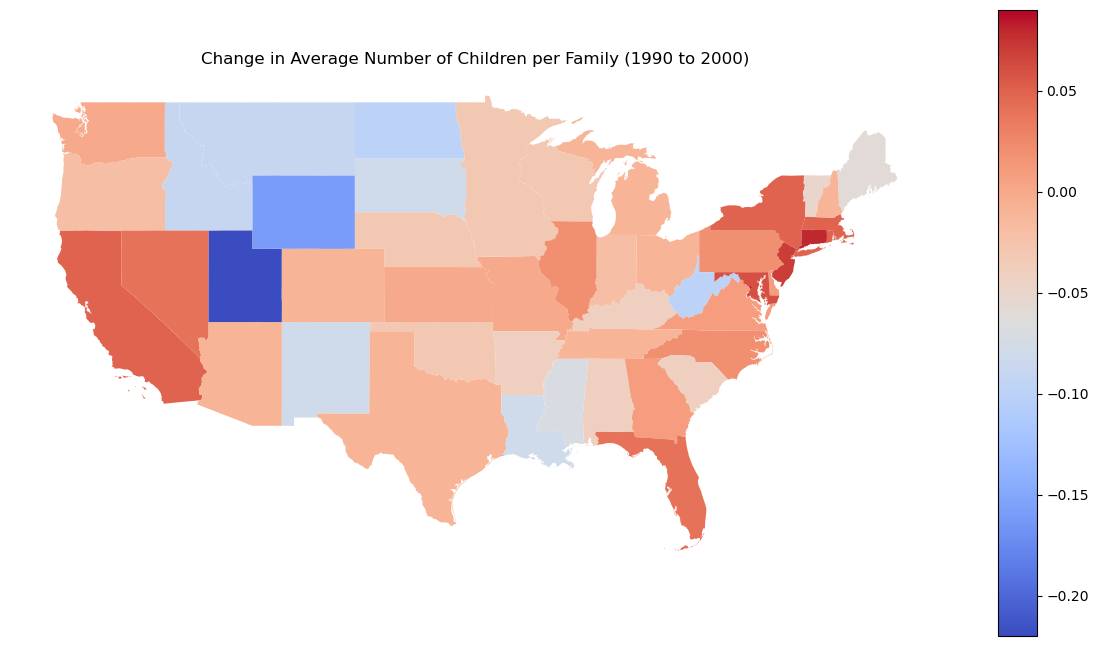

In [2]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import os

# Using current directory as working directory base
BASE_DIR = os.getcwd()

# Loading data and state shapefiles
data_path_1990 = os.path.join(BASE_DIR, 'data', 'family_size', '1990familydata.csv')
data_path_2000 = os.path.join(BASE_DIR, 'data', 'family_size', '2000familydata.csv')
shapefile_path = os.path.join(BASE_DIR, 'data', 'cb_2018_us_state_5m')
population_data_1990 = pd.read_csv(data_path_1990)
population_data_2000 = pd.read_csv(data_path_2000)
shapefile_data = gpd.read_file(shapefile_path)

# Calculating change from 1990 to 2000
population_data_2000['Change'] = (population_data_2000['Average'] - population_data_1990['Average'])

# Fixing errors in state and population data
population_data_2000['Area_name'] = population_data_2000['Area_name'].str.strip()
shapefile_data['NAME'] = shapefile_data['NAME'].str.strip()

# Filtering to exclude territories, Alaska, and Hawaii
continental_states = shapefile_data[~shapefile_data['STUSPS'].isin(['AK', 'HI', 'PR', 'VI', 'MP', 'GU', 'AS'])]

# Merging the population data with the states shapefile
merged = continental_states.merge(population_data_2000, left_on='NAME', right_on='Area_name', how='inner')


# Mapping data
fig, ax = plt.subplots(1, 1, figsize=(15, 10))
merged.plot(column='Change', cmap='coolwarm', legend=True, ax=ax)
plt.title(r'Change in Average Number of Children per Family (1990 to 2000)')
plt.axis('off')
plt.show()